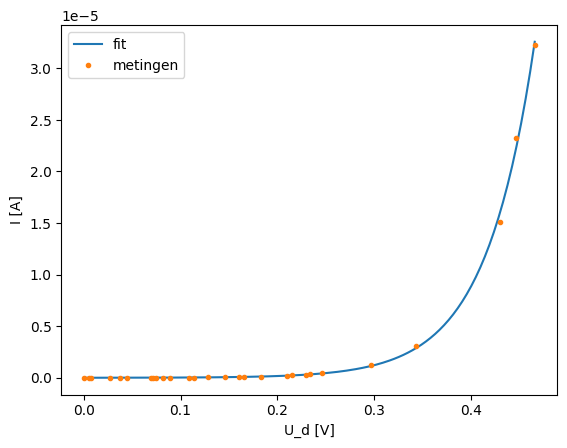

De waarde van de idealiteitsfactor n = 1.98 ± 0.0447
I_0 = 8.753124625872524e-09 A
n = 1.9750318752511637


In [ ]:
#BOLTZMAN 
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

U_Bron = np.array([0.0, 0.3, 0.11, 0.18, 0.28, 0.29, 0.33, 0.36, 0.44, 0.46, 
                   0.52, 0.59, 0.65, 0.74, 0.67, 0.85, 0.87, 0.93, 0.02, 0.03, 0.15, 1.00, 0.95, 1.22, 1.44,
                   2.02, 2.49, 2.66, 2.96, 3.32, 4.11, 4.26, 2.24])
U_R1 = np.array([0.003e-3, 0.003e-3, 0.004e-3, 0.012e-3, 0.036e-3, 0.039e-3, 0.054e-3, 0.067e-3, 0.104e-3,
                  0.127e-3, 0.175e-3, 0.279e-3, 0.370e-3, 0.578e-3, 0.396e-3, 1.006e-3, 1.115e-3, 
                  1.434e-3, 0.005e-3, 0.002e-3, 0.009e-3, 2.042e-3, 1.633e-3, 5.822e-3,14.414e-3, 70.771e-3,
                  151.751e-3, 183.480e-3, 0.23966, 0.31282, 0.47942, 0.511080, 109.300e-3])

U_Bron = U_Bron[0:-5]
U_R1 = U_R1[0:-5]

R_1 = 4700  #De weerstand waar we de spanning er van hebben gemeten, in ohm
R_2 = 1000
R_3 = 330


U = R_3 / (R_2+R_3) * U_Bron
U_d = U - U_R1
I = U_R1 / R_1

q = -1.602176634e-19  # negatieve elementaire lading, C
k_B = 1.380649e-23   # J/K
T = 23.8 + 273.15    # kelvin

def diode(U_d, I_0, n):
    return I_0 * (np.exp(-q * U_d / (n * k_B * T)-1))

params, cov = curve_fit(
    diode, U_d, I)


#onz_U_Bron = U_Bron
#onz_U_R1 = U_R1*(procent aflezeing) + (bereik)*()
#onz_Ud = np.sqrt((onz_U_R1 / R_1)**2 + (0.005 * I)**2)

x = np.linspace(min(U_d), max(U_d), 200)
y = diode(x, *params)


plt.plot(x, y, label="fit")
plt.plot(U_d, I, ".", label="metingen")
plt.xlabel("U_d [V]")
plt.ylabel("I [A]")
plt.legend()
plt.show()

onz_n = np.sqrt(cov[1, 1])
print('De waarde van de idealiteitsfactor n = {:.3g} ± {:.3g}'.format(params[1], onz_n))

print("I_0 =", params[0], "A")
print("n =", params[1])






<>:6: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:6: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\mlzha\AppData\Local\Temp\ipykernel_13888\3985137448.py:6: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  plt.ylabel('$\Delta I$ ($A$)')


<function matplotlib.pyplot.show(close=None, block=None)>

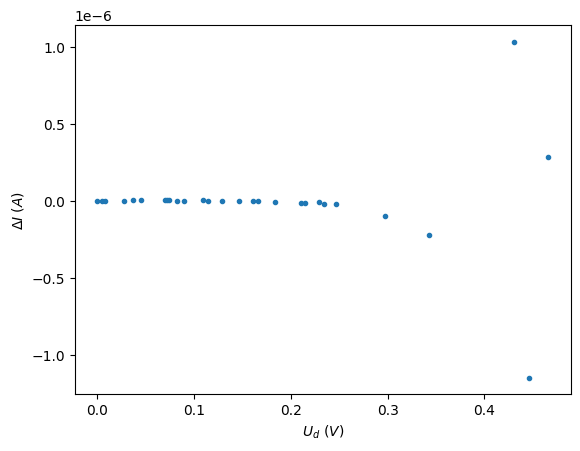

In [17]:
#residual analysis
y_res = diode(U_d, params[0], params[1])-I
plt.figure()
plt.plot(U_d, y_res, '.')
plt.xlabel('$U_d$ ($V$)')
plt.ylabel('$\Delta I$ ($A$)')
plt.show

In [ ]:
####agreement analysis
def func():
    
    print('Vul jouw gevonden waarde in: ')
    P = float(input())
    print('Vul jouw gevonden gevonden onzerkerheid in: ')
    U_p = float(input())

    print('vul de literatuur waarde in: ')
    Q = float(input())
    print('Vul de onzekerheid van de literatuur in: ')
    U_q = float(input())

    val_diff = np.abs(P - Q)
    print('De waarde verschil tussen gevonden en literatuur waarde is {:.3f}'.format(val_diff))
    if val_diff < 2*np.sqrt(U_p**2 + U_q**2):
        print('Je hebt common waarde')
    else:
        print("Je hebt geen common waarde")

func()

Vul jouw gevonden waarde in: 
